# Detecting acute stress from wearable sensors (WESAD)

**Jillian Melbourne** · HSE.751, Fall 2026

An end-to-end, reproducible pipeline: raw chest and wrist signals → 60-second window features → validation and quality control → descriptive and inferential analysis → (next) supervised classification of stress vs. non-stress.

**How to run:** choose **Runtime → Run all**. No uploads are needed: the first code cell fetches the project code and the saved feature table from GitHub. Use the **run settings** form in section 3 to upload your own feature table or to rebuild features from the raw WESAD files.

**Where the code lives.** The signal-processing and helper functions are in the `src/wesad/` package of the repository, so this notebook can focus on decisions and results:

| Module | Contents |
|---|---|
| `config.py` | `PipelineConfig`: every setting (window length, filters, quality thresholds) in one place |
| `loading.py` | loading and validating raw WESAD files and window-level feature tables |
| `features.py` | raw signals → one row per 60-second window, with quality flags |
| `analysis.py` | baseline normalization and effect sizes |
| `plots.py` | figure helpers |

| # | Section |
|---|---|
| 1 | Dataset selection |
| 2 | Dataset overview and project plan |
| 3 | Setup and run settings |
| 4 | Data input and validation |
| 5 | Single-participant deep dive (raw signals) |
| 6 | Feature pipeline |
| 7 | Cohort overview and data quality |
| 8 | Descriptive statistics |
| 9 | Baseline normalization |
| 10 | Effect sizes |
| 11 | Data quality notes |
| 12 | Summary and next steps |

## 1. Dataset selection

**Dataset:** WESAD (Wearable Stress and Affect Detection)
**Source:** UC Irvine Machine Learning Repository, https://archive.ics.uci.edu/dataset/465/wesad+wearable+stress+and+affect+detection

**Why I selected it.** My background is in signal processing for deep brain stimulation and wearables, so WESAD feels like familiar territory with new tools. It contains chest (ECG, EDA, respiration, temperature, EMG, acceleration) and wrist (blood volume pulse, EDA, temperature, acceleration) recordings from 15 participants during a lab stress protocol. Stress is hard to measure beyond self-report yet has major health effects, and wearables offer a promising way to quantify it passively. This project lets me build a complete pipeline from raw signal processing through model evaluation.

| Requirement | Met? | How WESAD meets it |
|---|---|---|
| Binary classification | ✅ | Stress (study label 2) vs. non-stress (baseline + amusement, labels 1 and 3) |
| ≥ 300 observations | ✅ | Each observation is a 60-second window; ~65 per participant × 15 participants ≈ 1,000 |
| ≥ 10 predictors | ✅ | Features engineered per window from both devices (heart rate, HRV, EDA, breathing rate, skin temperature, movement)

## 2. Dataset overview and project plan

S2 is a 27-year-old right-handed man (wrist sensor on the left). His protocol order was baseline → stress → meditation → amusement → meditation.

**Dataset structure.** One pickle holds 10 signal arrays plus a label array, with no missing values. The chest arrays have 4,255,300 rows at 700 Hz. The wrist arrays have between 24,316 rows (EDA and temperature, 4 Hz) and 389,056 rows (BVP, 64 Hz). Every array works out to the same **6,079 s (1 h 41 min 19 s)**, because the authors trimmed both devices to the same synced span. There is no timestamp column; time = row number ÷ sampling rate.

**Target variable.** The `label` array codes the protocol condition at 700 Hz. The binary target is stress (label 2) vs. non-stress (baseline 1 + amusement 3).

**Predictor variables.** There are six chest signals (ECG, EDA, respiration, temperature, EMG, 3-axis acceleration) and four wrist signals (BVP, EDA, temperature, 3-axis acceleration). Each 60-second window is summarized into 15 predictors (section 6):
- heart rate from chest ECG and wrist BVP
- heart rate variability (RMSSD) from chest ECG
- chest and wrist EDA level, chest EDA slope, count of wrist skin conductance responses
- breathing rate and breath-to-breath variability
- chest and wrist temperature, wrist temperature slope
- EMG amplitude (upper trapezius)
- movement variability on each device

Section 9 adds a **baseline-normalized** copy of every predictor (each person's values expressed relative to their own baseline).

### Project plan
- **Proposed prediction problem:** Detect physiological stress from wearable sensor data. Using chest (RespiBAN) and wrist (Empatica E4) recordings from the 15 WESAD participants, predict whether a person was under stress during a given 60-second window, using features engineered from heart rate, HRV, EDA, respiration, skin temperature, muscle activity and movement.
- **Target variable:** Binary stress, where 1 is the Trier Social Stress Test period (WESAD label 2) and 0 is non-stress (baseline and amusement, labels 1 and 3). Transitions, meditation, and "ignore" periods are excluded. Each observation is one 60-second window (30-second step), giving roughly 1,000 windows across all participants.
- **Candidate evaluation metrics:** F1 score on the stress class as the primary metric, with AUROC and balanced accuracy as supporting metrics. Stress is a minority of the usable time, so accuracy would be misleading. Models would be evaluated with leave-one-subject-out cross-validation, because overlapping windows from the same person would otherwise leak between training and test sets and inflate performance.

## 3. Setup and run settings

### 3.1 Get the project code
When the notebook is opened on its own (for example from a Colab link), this cell downloads the repository from GitHub so the `src/wesad` package and the saved feature table are available. When the notebook is already inside the repository, it does nothing.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/JillianMelbourne/WESAD-Stress-Detection.git"
REPO_DIR = "WESAD-Stress-Detection"

if not Path("src/wesad").exists():                       # not running from inside the repository
    if not Path(REPO_DIR).exists():
        print(f"Downloading the project from {REPO_URL} ...")
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)
if not Path("src/wesad").exists():
    raise FileNotFoundError(f"src/wesad was not found in {Path.cwd()}. The GitHub repository may not have "
                            "the latest version yet; push it, delete the downloaded folder, and run again.")
if str(Path("src").resolve()) not in sys.path:
    sys.path.insert(0, str(Path("src").resolve()))
print(f"Working directory: {Path.cwd()}")

Working directory: /home/claude/repo


### 3.2 Imports

In [2]:
import inspect
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy

from wesad import analysis, features, loading, plots
from wesad.config import (CONDITION_ORDER, EXCLUDE_FEATURES, README_NOTES, SUBJECTS,
                          PipelineConfig)

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scipy {scipy.__version__} | matplotlib {matplotlib.__version__}")

Python 3.13.16 | numpy 2.5.3 | pandas 3.0.5 | scipy 1.18.1 | matplotlib 3.11.2


### 3.3 Run settings
In Colab this cell shows as a form with drop-down menus. The defaults let **Run all** finish without any input.

| Setting | Options |
|---|---|
| `DATA_SOURCE` | **Use saved feature table** (default): the 1,015-window table for all 15 participants in `data/processed/`. <br>**Upload my own feature table**: a CSV with one row per window, a `subject` column, a 0/1 `stress` column and numeric feature columns (section 4 checks it). <br>**Rebuild from raw WESAD files**: re-runs feature extraction on the pickles in `data/raw/` (all 15 take a few minutes). |
| `UPLOAD_PATH` | Only for uploads outside Colab: path to the CSV. In Colab, leave it empty and a file picker opens. |
| `DEEP_DIVE_SUBJECT` | Participant shown in section 5. Needs that participant's raw file; skipped otherwise. |
| `SAVE_FIGURES` | Save every figure to `figures/`. |

Pipeline settings (window length, filter bands, quality thresholds) are fields of `PipelineConfig`; pass a different value here, e.g. `PipelineConfig(window_s=30)`, and choose **Rebuild** to apply it.

In [3]:
DATA_SOURCE = "Use saved feature table"  # @param ["Use saved feature table", "Upload my own feature table", "Rebuild from raw WESAD files"]
UPLOAD_PATH = ""  # @param {type:"string"}
DEEP_DIVE_SUBJECT = "S2"  # @param ["S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9", "S10", "S11", "S13", "S14", "S15", "S16", "S17"]
SAVE_FIGURES = True  # @param {type:"boolean"}

cfg = PipelineConfig(save_figures=SAVE_FIGURES)

# ---- check the settings before anything runs ---------------------------------
VALID_SOURCES = ["Use saved feature table", "Upload my own feature table", "Rebuild from raw WESAD files"]
if DATA_SOURCE not in VALID_SOURCES:
    raise ValueError(f"DATA_SOURCE must be one of {VALID_SOURCES}; got {DATA_SOURCE!r}")
if DEEP_DIVE_SUBJECT not in SUBJECTS:
    raise ValueError(f"DEEP_DIVE_SUBJECT must be one of {SUBJECTS}; got {DEEP_DIVE_SUBJECT!r}")
print(f"Data source: {DATA_SOURCE}")
print(f"Window: {cfg.window_s} s, step {cfg.step_s} s | target map (WESAD label -> stress): {cfg.target_map}")

Data source: Use saved feature table
Window: 60 s, step 30 s | target map (WESAD label -> stress): {1: 0, 3: 0, 2: 1}


## 4. Data input and validation

The cell below loads the feature table from the chosen source and adapts when something is missing:

- **Saved table:** read `data/processed/wesad_windows.csv`. If its recorded settings differ from `cfg`, a warning says so.
- **Upload:** open a file picker (Colab) or read `UPLOAD_PATH`.
- **Rebuild:** run the feature pipeline on the raw files. If no raw files are present, fall back to the saved table with a message instead of failing.

Every table, whatever its source, then goes through `validate_feature_table`, which checks for the required columns, a 0/1 target, enough windows in each class and at least two participants. It also drops (and reports) rows without a target and features that are mostly empty. A profile of every feature and a confirmation message follow.

In [4]:
def load_from_source(source):
    """Return (raw table, description of where it came from) for the chosen DATA_SOURCE."""
    if source == "Rebuild from raw WESAD files":
        present = [s for s in SUBJECTS if loading.raw_available(s, cfg)]
        if present:
            print(f"Rebuilding features from {len(present)} raw file(s) in {cfg.data_dir}/ ...")
            return features.build_feature_table(cfg, present), f"rebuilt from raw files ({len(present)} participants)"
        print(f"No raw WESAD files found in {cfg.data_dir}/, so falling back to the saved feature table.")
        source = "Use saved feature table"

    if source == "Upload my own feature table":
        path = Path(UPLOAD_PATH) if UPLOAD_PATH else loading.upload_feature_table()
        if not path.exists():
            raise FileNotFoundError(f"UPLOAD_PATH {path} does not exist.")
        return pd.read_csv(path), f"uploaded file {path.name}"

    if not cfg.feature_table.exists():
        raise FileNotFoundError(f"{cfg.feature_table} is missing. Re-download the repository or choose another DATA_SOURCE.")
    if features.saved_settings_match(cfg) is False:
        print("Warning: the saved table was built with different settings from cfg. "
              "Choose 'Rebuild from raw WESAD files' to apply the current settings.")
    return pd.read_csv(cfg.feature_table), f"saved table {cfg.feature_table}"


table, source_note = load_from_source(DATA_SOURCE)
feats, FEATURES, notes = loading.validate_feature_table(table)   # raises with a full list of problems if invalid
for note in notes:
    print("Note:", note)

# Is this the WESAD pipeline's own output? Several later steps (readme notes, quality flags, conditions) depend on it.
IS_WESAD_TABLE = set(features.FEATURE_COLUMNS) <= set(feats.columns) and "condition" in feats.columns
HAS_FLAGS = "flag_any" in feats.columns

print(f"\n✅ Dataset loaded and validated ({source_note}): {len(feats):,} windows, {len(FEATURES)} features, "
      f"{feats['subject'].nunique()} participants, {feats['stress'].mean():.0%} stress windows.")


✅ Dataset loaded and validated (saved table data/processed/wesad_windows.csv): 1,015 windows, 15 features, 15 participants, 30% stress windows.


### 4.1 Data profile
One row per feature: data type, share missing, and range. Missing values are expected in two places in the WESAD table: chest temperature for S2 and S17 (excluded on purpose, see section 7) and occasional windows where too few heartbeats were detected.

In [5]:
display(loading.profile_table(feats, FEATURES))

,dtype,% missing,mean,sd,min,max
feature,,,,,,
chest_hr_bpm,float64,0.000,79.837,18.147,50.589,148.737
chest_rmssd_ms,float64,0.000,51.422,34.149,2.243,202.532
wrist_hr_bpm,float64,0.000,79.321,12.094,55.858,142.373
chest_eda_uS,float64,0.000,4.584,3.434,0.636,19.969
chest_eda_slope_uS_per_min,float64,0.000,0.006,0.316,-3.393,5.652
wrist_eda_uS,float64,0.000,1.965,2.653,0.094,15.612
wrist_scr_count,int64,0.000,8.817,8.164,0.000,45.000
resp_rate_bpm,float64,0.000,16.167,2.635,9.000,25.000
resp_interval_sd_s,float64,0.000,0.872,0.531,0.139,3.262


## 5. Single-participant deep dive (raw signals)

Sections 5.1–5.4 look at one participant's raw recording (`DEEP_DIVE_SUBJECT`, S2 by default) to show what the features are made from. They need that participant's raw file at `data/raw/<subject>/<subject>.pkl`. If it is not there, these cells print a note and the rest of the notebook runs normally.

In [6]:
DEEP_DIVE = loading.raw_available(DEEP_DIVE_SUBJECT, cfg)
if DEEP_DIVE:
    subj = loading.load_subject(DEEP_DIVE_SUBJECT, cfg)          # validated on load
    sig = features.preprocess(subj, cfg)
    win = features.extract_windows(subj, cfg, sig)
    periods = plots.condition_periods(subj["label"])
    print(f"Loaded {DEEP_DIVE_SUBJECT}: passed validation; {len(win)} windows")
else:
    print(f"Skipping section 5: no raw file for {DEEP_DIVE_SUBJECT} in {cfg.data_dir}/. "
          f"To include it, download WESAD from UCI and place {DEEP_DIVE_SUBJECT}.pkl at "
          f"{cfg.data_dir / DEEP_DIVE_SUBJECT / (DEEP_DIVE_SUBJECT + '.pkl')}.")

Loaded S2: passed validation; 65 windows


### 5.1 Recording structure
Each pickle is a nested dictionary: `label` (one condition code per 700 Hz sample) and `signal`, with six chest channels (RespiBAN, all 700 Hz) and four wrist channels (Empatica E4, 4–64 Hz). There is **no time column**: `seconds = row number / sampling rate`, and the authors trimmed both devices so row 0 of every array is the same moment.

In [7]:
if DEEP_DIVE:
    display(loading.describe_recording(subj))

,device,channel,shape,fs_Hz,duration_min,units,n_NaN
0,chest,ACC,"(4255300, 3)",700,101.317,g,0
1,chest,ECG,"(4255300, 1)",700,101.317,mV,0
2,chest,EMG,"(4255300, 1)",700,101.317,mV,0
3,chest,EDA,"(4255300, 1)",700,101.317,µS,0
4,chest,Temp,"(4255300, 1)",700,101.317,°C,0
5,chest,Resp,"(4255300, 1)",700,101.317,%,0
6,wrist,ACC,"(194528, 3)",32,101.317,g,0
7,wrist,BVP,"(389056, 1)",64,101.317,a.u.,0
8,wrist,EDA,"(24316, 1)",4,101.317,µS,0
9,wrist,TEMP,"(24316, 1)",4,101.317,°C,0


### 5.2 Target variable
| `stress` | WESAD label | Condition |
|---|---|---|
| **1** | 2 | Stress: Trier Social Stress Test (public speech + mental arithmetic) |
| **0** | 1, 3 | Baseline (reading magazines) and amusement (funny videos) |
| excluded | 0, 4, 5–7 | Transitions, meditation, and "ignore" periods |

In [8]:
if DEEP_DIVE:
    display(loading.target_summary(subj["label"], cfg))

,condition,minutes,% of recording,binary target
label,,,,
0,transient,51.017,50.354,excluded
1,baseline,19.067,18.819,0 (non-stress)
2,stress,10.250,10.117,1 (stress)
3,amusement,6.033,5.955,0 (non-stress)
4,meditation,12.800,12.634,excluded
6,ignore,1.083,1.069,excluded
7,ignore,1.067,1.053,excluded


### 5.3 Figures 1–2: raw signals
**Figure 1** shows the whole session with conditions shaded (white gaps are transitions or ignored periods). **Figure 2** shows the same 10 seconds of chest ECG and wrist BVP one minute into baseline and into stress; each heartbeat should be followed a fraction of a second later by a pulse at the wrist.

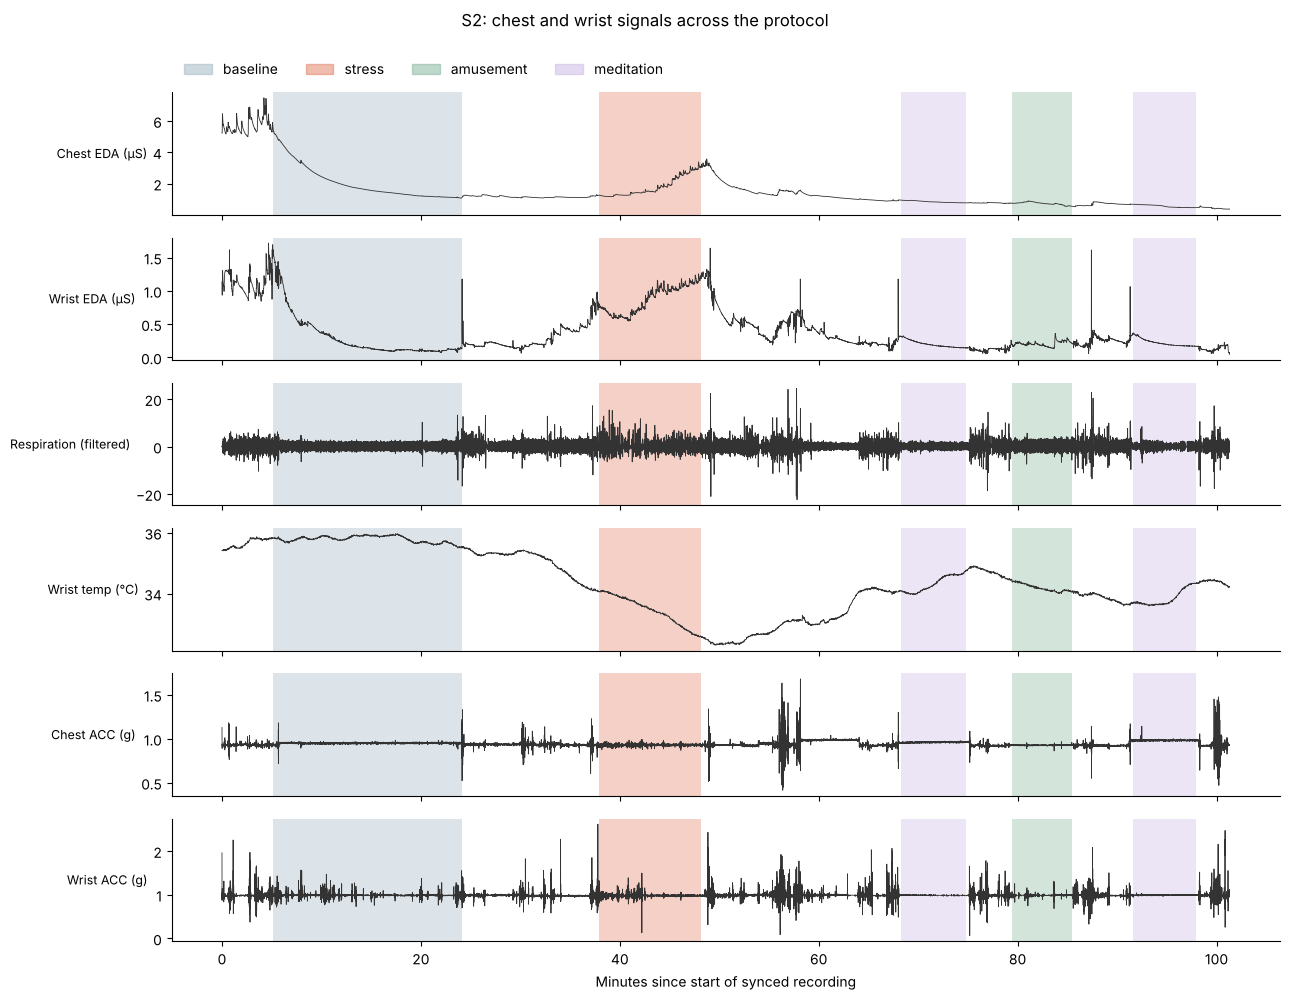

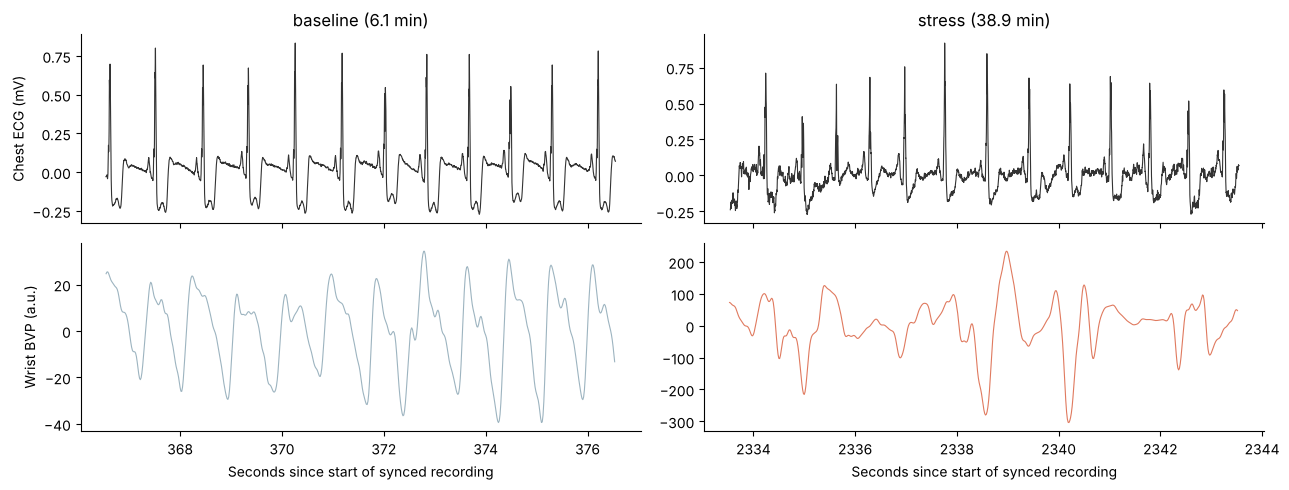

In [9]:
if DEEP_DIVE:
    fig = plots.aligned_session(sig, periods, DEEP_DIVE_SUBJECT)
    plots.save_fig(fig, f"fig1_{DEEP_DIVE_SUBJECT}_aligned_session", cfg)
    plt.show()
    fig = plots.ecg_vs_bvp(subj)
    plots.save_fig(fig, f"fig2_{DEEP_DIVE_SUBJECT}_ecg_vs_bvp", cfg)
    plt.show()

### 5.4 Figures 3–4: window features
**Figure 3:** each dot is one 60-second window; hollow dots carry at least one quality flag (section 6). **Figure 4:** feature distributions by condition.

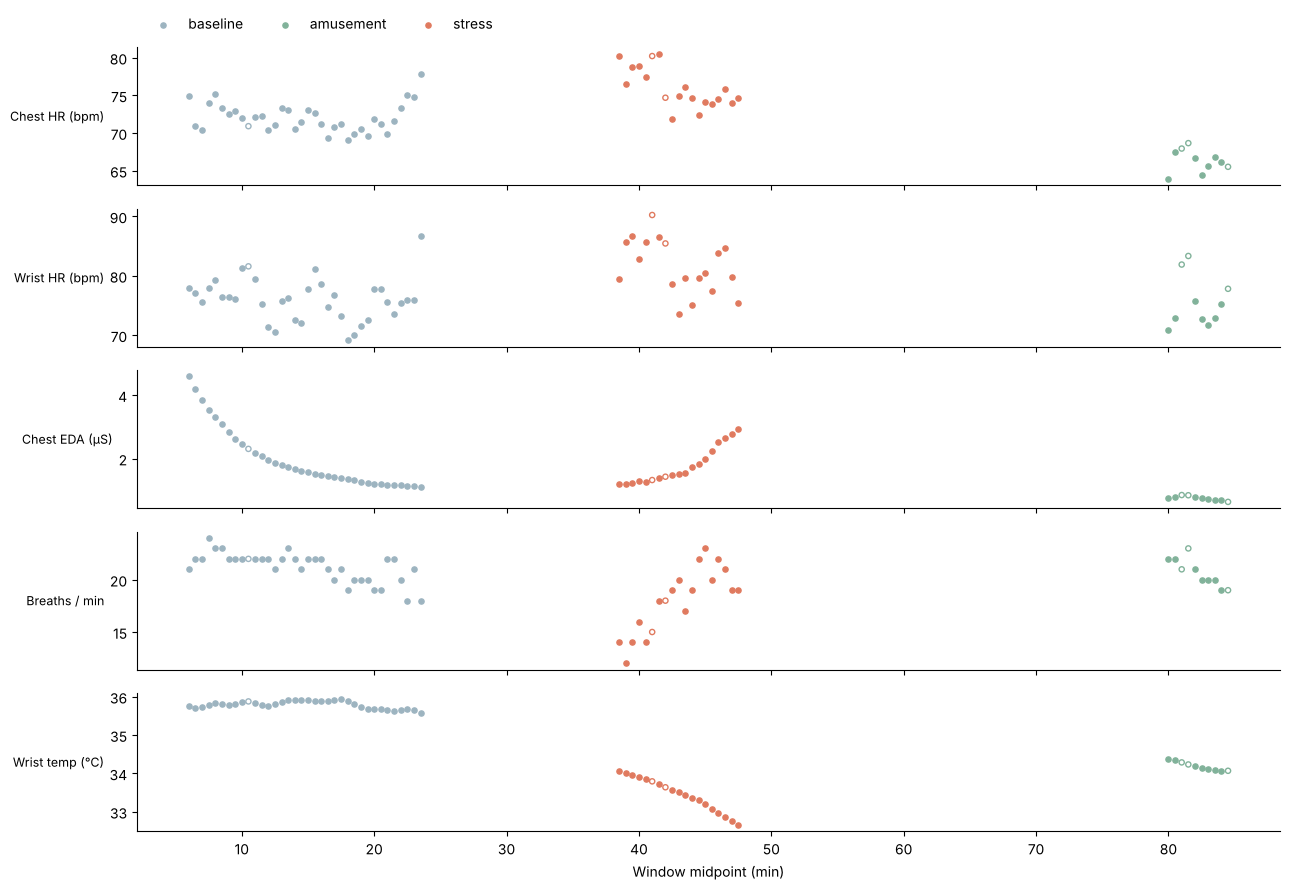

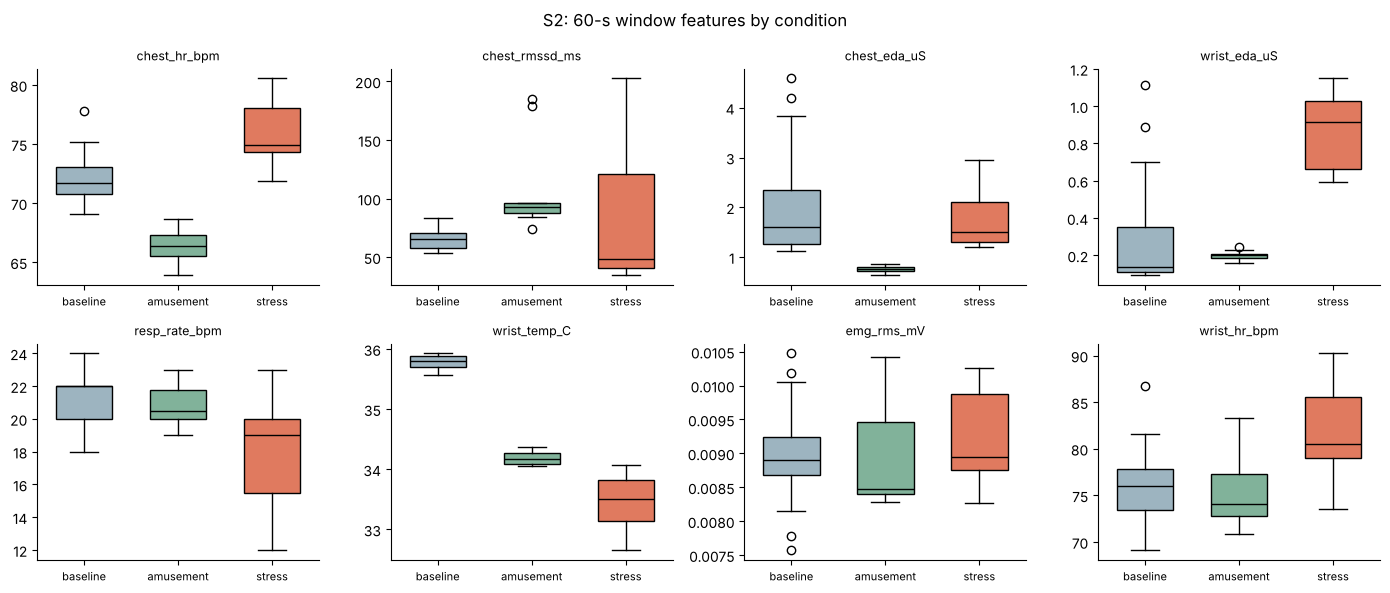

In [10]:
if DEEP_DIVE:
    fig = plots.features_over_time(win, [("chest_hr_bpm", "Chest HR (bpm)"), ("wrist_hr_bpm", "Wrist HR (bpm)"),
                                         ("chest_eda_uS", "Chest EDA (µS)"), ("resp_rate_bpm", "Breaths / min"),
                                         ("wrist_temp_C", "Wrist temp (°C)")])
    plots.save_fig(fig, f"fig3_{DEEP_DIVE_SUBJECT}_features_over_time", cfg)
    plt.show()
    fig = plots.condition_boxplots(win, ["chest_hr_bpm", "chest_rmssd_ms", "chest_eda_uS", "wrist_eda_uS",
                                         "resp_rate_bpm", "wrist_temp_C", "emg_rms_mV", "wrist_hr_bpm"],
                                   f"{DEEP_DIVE_SUBJECT}: 60-s window features by condition")
    plots.save_fig(fig, f"fig4_{DEEP_DIVE_SUBJECT}_feature_distributions", cfg)
    plt.show()

## 6. Feature pipeline

`src/wesad/features.py` turns each participant's raw recording into one row per **60-second window** (30-second step):

1. `preprocess`: filters each whole recording once (zero-phase Butterworth filters) and downsamples where that loses nothing.
2. `window_features`: computes the predictors for one window.
3. `extract_windows`: slides the window across the recording, keeps windows whose label is in `target_map` and at least `min_label_purity` pure, sets channels listed in `EXCLUDE_FEATURES` to missing, and adds quality flags.
4. `build_feature_table`: runs every participant one at a time (each raw file is ~1 GB), skips any that are missing or fail validation, and saves the table with the settings used.

| Predictor | Source | Definition |
|---|---|---|
| `chest_hr_bpm`, `chest_rmssd_ms` | ECG | Mean HR and RMSSD from R-peaks (QRS-energy detector) |
| `wrist_hr_bpm` | BVP | Mean HR from pulse peaks |
| `chest_eda_uS`, `chest_eda_slope_uS_per_min` | chest EDA | Mean level and linear trend |
| `wrist_eda_uS`, `wrist_scr_count` | wrist EDA | Mean level and number of skin conductance responses |
| `resp_rate_bpm`, `resp_interval_sd_s` | Resp | Breaths per minute and SD of breath-to-breath intervals |
| `chest_temp_C`, `wrist_temp_C`, `wrist_temp_slope_C_per_min` | Temp | Mean temperatures and wrist trend |
| `emg_rms_mV` | EMG | RMS amplitude after a 20 Hz high-pass |
| `chest_acc_sd_g`, `wrist_acc_sd_g` | ACC | SD of acceleration magnitude (movement) |

| Quality flag | Rule | Likely cause |
|---|---|---|
| `flag_hr_missing` | chest or wrist HR missing (too few valid beats) | electrode or optical signal lost |
| `flag_hr_disagree` | chest and wrist HR differ by more than 10 bpm | BVP motion artifact |
| `flag_ecg_artifact` | more than 20% of chest beat intervals implausible | noisy ECG |
| `flag_temp_range` | skin temperature outside 25–40 °C | sensor detached |
| `flag_eda_contact` | wrist EDA below 0.05 µS | electrodes not touching the skin |

The core of the feature step, for reference:

In [11]:
print(inspect.getsource(features.window_features))

def window_features(sig, t0, cfg: PipelineConfig):
    """All predictors for the window starting at t0 seconds, plus two beat-rejection rates used for QC."""
    w = cfg.window_s
    max_hr = cfg.hr_range_bpm[1]
    e = cut(sig, "ecg_energy", t0, w)
    pk, _ = signal.find_peaks(e, distance=int(60 / max_hr * FS_CHEST), height=0.3 * np.percentile(e, 99))
    b = cut(sig, "bvp", t0, w)
    bpk, _ = signal.find_peaks(b, distance=int(60 / max_hr * 64), prominence=0.3 * b.std())
    r = cut(sig, "resp", t0, w)
    rpk, _ = signal.find_peaks(r, distance=15, prominence=0.3 * r.std())
    breath_iv = np.diff(rpk) / 10
    we, ce, wt = cut(sig, "wrist_eda", t0, w), cut(sig, "chest_eda", t0, w), cut(sig, "wrist_temp", t0, w)
    scr, _ = signal.find_peaks(we, prominence=0.01, distance=4)
    hr_c, rmssd_c, rej_c = beats_to_hr(pk, FS_CHEST, cfg)
    hr_w, _, rej_w = beats_to_hr(bpk, 64, cfg)       # wrist RMSSD is not used: 64 Hz pulse timing is too coarse
    return {
        "chest_hr_bpm": hr_

## 7. Cohort overview and data quality
Windows per participant and condition, the share of windows with each quality flag, and notes from each participant's readme. Flagged windows are kept but marked so later steps can drop them or test their influence.

In [12]:
group_col = "condition" if "condition" in feats.columns else "stress"
cohort = feats.groupby("subject")[group_col].value_counts().unstack(fill_value=0)
cohort = cohort.reindex(analysis.subject_order(feats["subject"]))
if group_col == "condition":
    cohort = cohort.reindex(columns=[c for c in CONDITION_ORDER if c in cohort.columns])
cohort["total"] = cohort.sum(axis=1)
cohort["% stress"] = 100 * feats.groupby("subject")["stress"].mean().reindex(cohort.index)
if HAS_FLAGS:                                   # quality flags only exist in tables built by this pipeline
    flag_cols = [c for c in features.FLAG_COLUMNS + ["flag_any"] if c in feats.columns]
    pct = feats.groupby("subject")[flag_cols].mean().mul(100).reindex(cohort.index)
    cohort = cohort.join(pct.rename(columns=lambda c: "% " + c.replace("flag_", "")))
if IS_WESAD_TABLE:
    cohort["readme note"] = [README_NOTES.get(s, "") + (" Chest temp excluded." if s in EXCLUDE_FEATURES else "")
                             for s in cohort.index]
display(cohort)
if HAS_FLAGS:
    print(f"{feats['flag_any'].mean():.0%} of windows carry at least one quality flag; "
          f"most come from chest-wrist heart-rate disagreement.")

,baseline,amusement,stress,total,% stress,% hr_missing,% hr_disagree,% ecg_artifact,% temp_range,% eda_contact,% any,readme note
subject,,,,,,,,,,,,
S2,36,10,19,65,29.231,0.000,9.231,0.000,0.000,0.000,9.231,Chest temp excluded.
S3,36,11,20,67,29.851,0.000,43.284,0.000,0.000,0.000,43.284,Baseline recorded in a sunny workplace (skin t...
S4,37,10,19,66,28.788,0.000,4.545,0.000,0.000,0.000,4.545,
S5,38,10,19,67,28.358,0.000,19.403,0.000,0.000,0.000,19.403,May have fallen asleep during the first medita...
S6,37,10,20,67,29.851,0.000,2.985,0.000,0.000,0.000,2.985,Reported the TSST interview was not really str...
S7,37,11,19,67,28.358,0.000,14.925,0.000,0.000,0.000,14.925,
S8,37,10,21,68,30.882,0.000,14.706,0.000,0.000,0.000,14.706,Stressful day before the study; felt cold in t...
S9,37,10,19,66,28.788,0.000,1.515,0.000,0.000,0.000,1.515,Reported feeling ill on the study day.
S10,37,10,22,69,31.884,0.000,17.391,0.000,0.000,0.000,17.391,


17% of windows carry at least one quality flag; most come from chest-wrist heart-rate disagreement.


## 8. Descriptive statistics
Mean of each feature by condition (or by stress label for an uploaded table without conditions), plus the share of windows where the feature is missing.

In [13]:
desc = feats.groupby(group_col)[FEATURES].mean().T
if group_col == "condition":
    desc = desc[[c for c in CONDITION_ORDER if c in desc.columns]]
desc["% missing"] = 100 * feats[FEATURES].isna().mean()
display(desc)

condition,baseline,amusement,stress,% missing
chest_hr_bpm,72.357,72.539,97.402,0.000
chest_rmssd_ms,52.734,56.229,46.518,0.000
wrist_hr_bpm,74.795,74.892,89.955,0.000
chest_eda_uS,3.885,4.477,5.926,0.000
chest_eda_slope_uS_per_min,-0.043,-0.011,0.103,0.000
wrist_eda_uS,1.320,1.410,3.442,0.000
wrist_scr_count,6.359,5.346,15.142,0.000
resp_rate_bpm,16.136,17.154,15.712,0.000
resp_interval_sd_s,0.637,0.808,1.337,0.000
chest_temp_C,33.797,34.274,34.365,13.202


## 9. Baseline normalization
People differ a lot in resting heart rate, skin conductance and skin temperature, and pooled across participants those differences can be larger than the stress effect. Each feature is therefore re-expressed relative to the participant's own resting level:

$$x_{bz} = \frac{x - \bar{x}_{\text{rest}}}{s_{\text{all}}}$$

where $\bar{x}_{\text{rest}}$ is the mean of that participant's baseline windows and $s_{\text{all}}$ is the SD of all of that participant's windows. 0 means "typical for this person at rest", and units are comparable across people. The SD uses all windows because baseline is very stable for some signals (wrist EDA in particular), and dividing by its tiny SD gave values in the hundreds; it needs no labels, so no stress information enters this step.

**Adapts to the data:** if the table has no `condition` column, or some participant has no baseline windows, all non-stress windows are used as the resting reference instead, and the cell says so.

This mirrors how a wearable would calibrate on a short resting recording. One caveat for modelling: under leave-one-participant-out evaluation, the held-out person's own resting windows are used to normalize their test windows, which assumes a new user would provide such a recording.

**Figure 5:** each line is one participant, from mean non-stress value (left) to mean stress value (right), before and after normalization.

Resting reference: baseline windows
Saved normalized table to data/processed/wesad_windows_normalized.csv


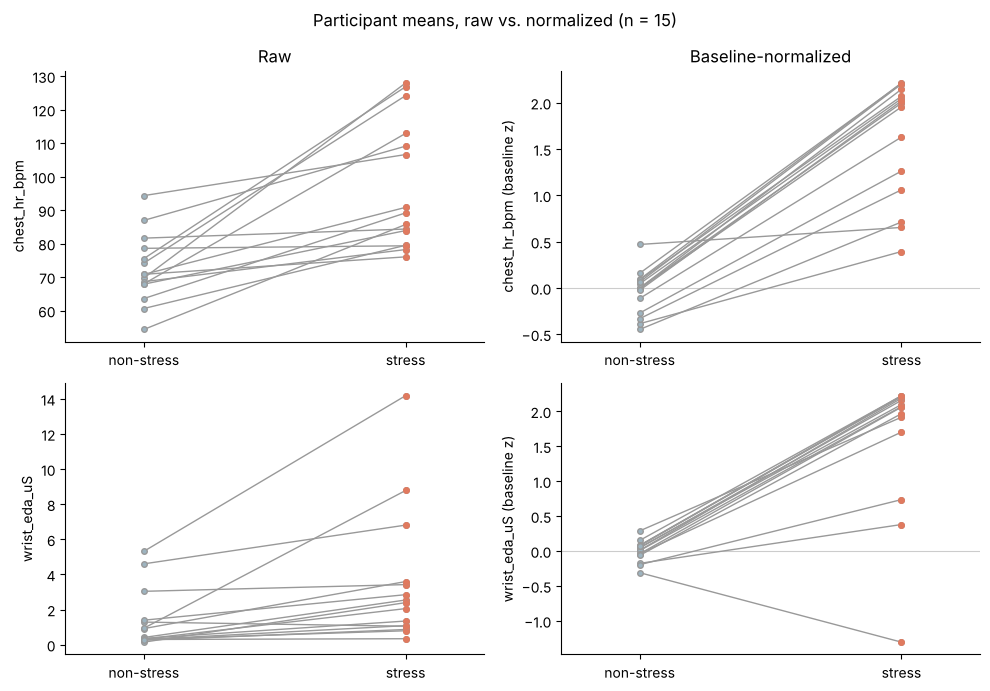

In [14]:
feats, reference = analysis.baseline_normalize(feats, FEATURES)
FEATURES_BZ = [f"{f}_bz" for f in FEATURES]
print(f"Resting reference: {reference}")
if DATA_SOURCE != "Upload my own feature table":
    feats.to_csv(cfg.processed_dir / "wesad_windows_normalized.csv", index=False)
    print(f"Saved normalized table to {cfg.processed_dir / 'wesad_windows_normalized.csv'}")

# show two familiar features if present, otherwise the first two features in the table
pair = [f for f in ("chest_hr_bpm", "wrist_eda_uS") if f in FEATURES] or FEATURES[:2]
fig, axes = plt.subplots(len(pair), 2, figsize=(10, 3.5 * len(pair)), squeeze=False)
for row, col in enumerate(pair):
    plots.slope_panel(axes[row, 0], feats, col, col)
    plots.slope_panel(axes[row, 1], feats, f"{col}_bz", f"{col} (baseline z)")
    axes[row, 1].axhline(0, color="#ccc", lw=0.8, zorder=0)
axes[0, 0].set_title("Raw")
axes[0, 1].set_title("Baseline-normalized")
fig.suptitle(f"Participant means, raw vs. normalized (n = {feats['subject'].nunique()})")
fig.tight_layout()
plots.save_fig(fig, "fig5_cohort_baseline_normalization", cfg)
plt.show()

## 10. Effect sizes: which features separate stress from non-stress?
For each feature, **Cohen's d** measures the difference between stress and non-stress windows in standard-deviation units:

$$d = \frac{\bar{x}_{\text{stress}} - \bar{x}_{\text{non-stress}}}{s_{\text{pooled}}}, \qquad s_{\text{pooled}} = \sqrt{\frac{(n_1 - 1)s_1^2 + (n_0 - 1)s_0^2}{n_1 + n_0 - 2}}$$

(|d| ≈ 0.2 small, 0.5 medium, 0.8 large). It is computed three ways:

- **within-participant d**, one per participant, summarized by the median and by how many participants show the same direction;
- **pooled raw d**: all windows together, raw values;
- **pooled normalized d**: all windows together, baseline-normalized values.

Within-participant d is inflated by overlapping windows and stable within-condition signals, so pooled normalized d is the better guide to how well a feature will separate people the model has not seen. The Mann–Whitney p-value treats windows as independent, which they are not; it is shown only as a rough guide (section 11).

In [15]:
d_by_subject, effects = analysis.effect_sizes(feats, FEATURES)
display(effects.style.format({"median within-participant d": "{:+.2f}", "pooled raw d": "{:+.2f}",
                              "pooled normalized d": "{:+.2f}", "Mann-Whitney p (normalized)": "{:.1e}"}))

,median within-participant d,same direction (n/N),pooled raw d,pooled normalized d,Mann-Whitney p (normalized)
feature,,,,,
wrist_eda_uS,+6.93,14/15,+0.85,+2.16,1.8e-78
chest_hr_bpm,+4.84,15/15,+1.77,+2.42,1.2e-103
chest_eda_uS,+4.78,14/15,+0.58,+2.14,1.1e-83
wrist_scr_count,+2.22,15/15,+1.28,+2.09,2.3e-90
resp_interval_sd_s,+2.00,15/15,+1.52,+1.74,3.0e-90
chest_acc_sd_g,+1.86,15/15,+0.55,+1.65,1.2e-87
wrist_hr_bpm,+1.84,15/15,+1.53,+1.82,6.7e-83
wrist_acc_sd_g,+1.57,13/15,+1.08,+0.97,2.0e-18
chest_temp_C,+1.45,13/13,+0.56,+1.41,6.2e-58


**Figure 6:** grey dots are participants, bars the median within-participant d, black diamonds the pooled normalized d; bars to the right mean the feature rises under stress. **Figure 7:** the same d per participant; a column of one colour means the feature works for everyone (* = readme note, see section 7; grey = not available).

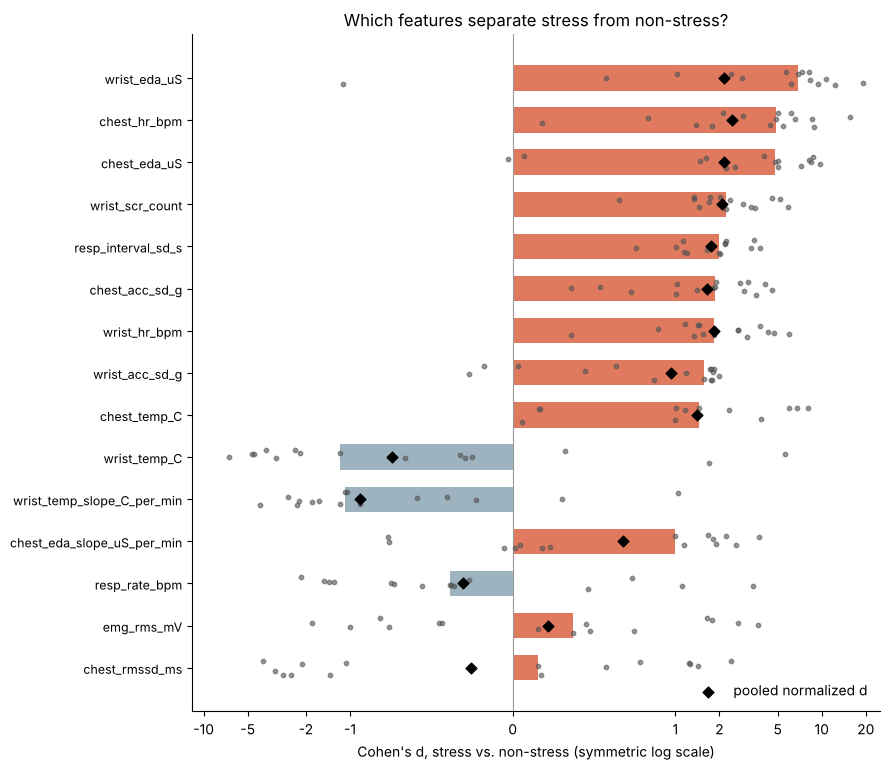

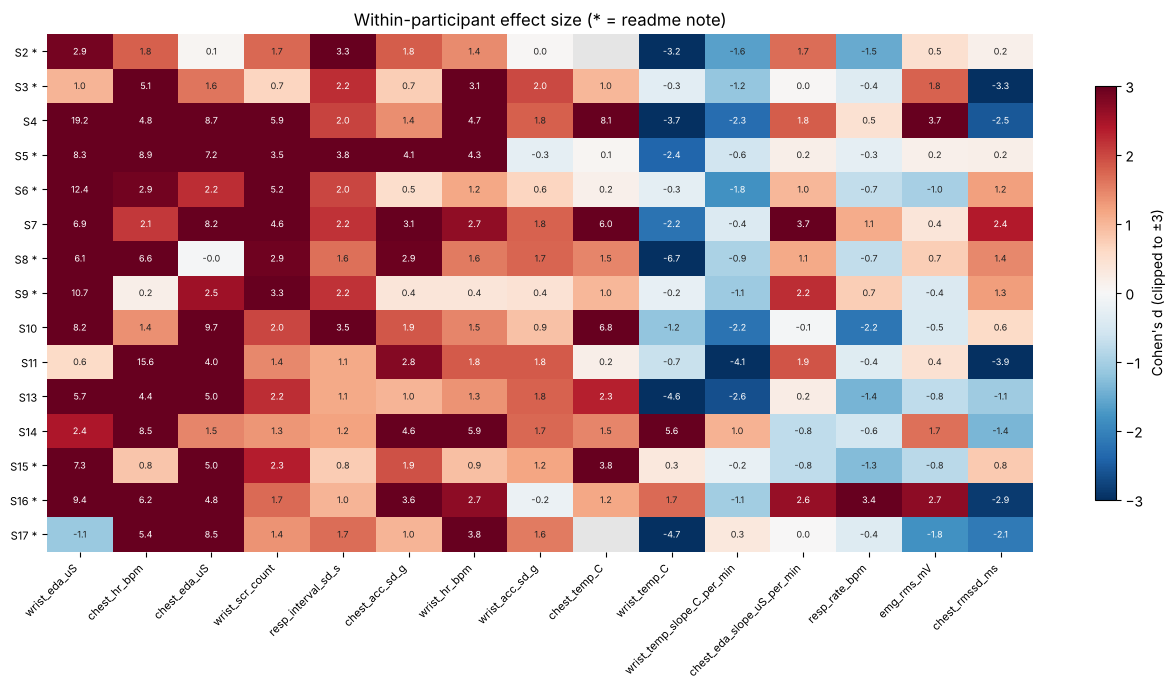

In [16]:
fig = plots.effect_size_chart(d_by_subject, effects)
plots.save_fig(fig, "fig6_cohort_effect_sizes", cfg)
plt.show()

starred = set(README_NOTES) | set(EXCLUDE_FEATURES) if IS_WESAD_TABLE else set()
fig, ax = plots.effect_heatmap(d_by_subject, starred)
ax.set_title("Within-participant effect size" + (" (* = readme note)" if starred else ""))
plots.save_fig(fig, "fig7_cohort_effect_heatmap", cfg)
plt.show()

## 11. Data quality notes
- **Participant-specific problems.** Chest temperature is excluded for S2 and S17 (sensor not fully attached). S6 and S15 reported the stress task was not really stressful or did not believe it, and S8 and S16 felt cold in the stress room, which confounds skin temperature.
- **Signal vs. noise.** Chest and wrist both measure heart rate, so their disagreement (`flag_hr_disagree`) is a per-window check on wrist motion artifact, most likely during the stress task's speech when participants stand and gesture. Some stress windows show chest HR far above wrist HR (e.g., S11), suggesting the ECG detector also counts T-waves while the participant talks.
- **Movement and speech confounds.** The stress task has participants stand and talk, so movement and breathing irregularity rise partly for mechanical reasons. They will help a classifier on WESAD but may not transfer to stress experienced while sitting still.
- **Class imbalance.** About 30% of usable windows are stress, so accuracy alone would be misleading.
- **Window dependence.** Windows overlap by 50% and come from only 15 people. Evaluation must hold out whole participants, and p-values that treat windows as independent are far too small.
- **No wrist HRV.** RMSSD from the 64 Hz wrist pulse came out at 170–350 ms against about 50 ms from the ECG, so it was left out.

## 12. Summary and next steps
- The pipeline turns raw chest and wrist recordings from 15 participants into 1,015 validated, quality-flagged 60-second windows with 15 predictors, and accepts a user's own feature table in the same format.
- Baseline normalization removes most of the between-person offset; EDA, heart rate and skin conductance responses rise under stress for nearly every participant, while chest RMSSD and EMG are inconsistent.
- **Next:** inferential tests at the participant level (Wilcoxon signed-rank on per-participant means; logistic regression with participant-clustered standard errors) and supervised classifiers evaluated with leave-one-participant-out cross-validation, with F1 on the stress class as the primary metric.